<a href="https://colab.research.google.com/github/va24nsh/Major-Project/blob/main/MixerSENet_Houston_B1_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MixerSENet — Hyperspectral Image Classification (Houston13)

This notebook implements the **MixerSENet** architecture from:  
> *"MixerSENet: A Lightweight Framework for Efficient Hyperspectral Image Classification"*  
> Alkhatib, Kumar Roy & Jamali — IEEE GRSL 2025  

**Notebook structure:**
1. Imports & Configuration
2. Utility Functions (data loading, PCA, patching, visualization)
3. FLOP Estimator
4. Model Architecture — SE Block
5. Model Architecture — Activation Block
6. **Model Architecture — Mixer Block** *(isolated for experimentation)*
7. Model Architecture — MixerSENet Assembly
8. Dataset Loading & Preprocessing (Houston13)
9. Train/Val/Test Split & Patch Extraction
10. Model Construction & Summary
11. Training
12. Evaluation (OA, AA, Kappa)
13. Classification Map Generation & Visualization
14. Save Results

---
## Cell 1 — Imports & Configuration
All third-party imports and user-configurable paths / hyperparameters are collected here so nothing else in the notebook needs editing for a standard run.

In [16]:
!pip install spectral
!pip install tensorflow

import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpts
import spectral
import scipy.io as sio

from scipy.io import loadmat
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import minmax_scale
from sklearn.metrics import cohen_kappa_score, accuracy_score, confusion_matrix
from tqdm import tqdm

import tensorflow as tf
from tensorflow import keras
from keras import layers
from tensorflow.keras.callbacks import ModelCheckpoint

# ────────────────────────── USER CONFIGURATION ──────────────────────────
# Path to the folder that contains the .mat dataset files.
# Change this to wherever your Houston13 dataset files are stored.
# DATASET_DIR = os.path.join(os.getcwd(), 'datasets')
DATASET_DIR = '/content/drive/MyDrive/datasets'

# Hyperparameters (matching the original paper defaults)
NUM_PCA_COMPONENTS = 15       # Number of PCA components for dimensionality reduction
WINDOW_SIZE        = 9        # Spatial patch size (window_size x window_size)
DEPTH              = 5        # Number of mixer blocks stacked
FILTERS            = 64       # Number of filters in each mixer / conv layer
EPOCHS             = 100      # Training epochs
BATCH_SIZE         = 64       # Training batch size
LEARNING_RATE      = 5e-4     # Initial Adam learning rate
VAL_SPLIT_RATIO    = 0.50     # Fraction of training samples used for validation
SE_RATIO           = 8        # Squeeze-and-Excitation reduction ratio
CHECKPOINT_PATH    = 'Houston_MixerSE_B1_(1).h5'  # Best-weights checkpoint filename

print('TensorFlow version:', tf.__version__)
print('Dataset directory :', DATASET_DIR)

TensorFlow version: 2.21.0
Dataset directory : /content/drive/MyDrive/datasets


In [17]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## Cell 2 — Utility Functions
Core helpers ported verbatim from `utils.py`:  
- `get_img_indexes` — extract labelled pixel coordinates from a ground-truth map  
- `createImageCubes` — cut spatial patches around each pixel with zero-padding  
- `splitTrainTestSet` — stratified train/test split wrapper  
- `applyPCA` — dimensionality reduction + min-max normalisation  
- `predict_by_batching` — memory-safe batched inference  
- `get_class_map` — produce a full predicted classification map  
- `img_display` — plot RGB or class-coloured images  
- `display_history` — plot training/validation loss & accuracy curves

In [18]:
# ──────────────────────────────────────────────────────────────────────────
# get_img_indexes: returns pixel indices and 0-based labels from a 2-D
# ground-truth map.  When removeZeroindexes=True only labelled (non-zero)
# pixels are returned.
# ──────────────────────────────────────────────────────────────────────────
def get_img_indexes(class_map, removeZeroindexes=True):
    if removeZeroindexes:
        indices = np.argwhere(class_map != 0)
    else:
        indices = np.argwhere(class_map != None)
    labels = class_map[indices[:, 0], indices[:, 1]]
    indices = [tuple(idx) for idx in indices]
    return indices, np.array(labels.tolist()) - 1


# ──────────────────────────────────────────────────────────────────────────
# createImageCubes: extracts (windowSize x windowSize x bands) patches
# centred on each index from a zero-padded version of the image.
# ──────────────────────────────────────────────────────────────────────────
def createImageCubes(X, indices, windowSize):
    margin = windowSize // 2
    N, M, P = X.shape
    X_padded = np.zeros((N + 2 * margin, M + 2 * margin, P))
    x_offset = margin
    y_offset = margin
    X_padded[x_offset:N + x_offset, y_offset:M + y_offset, :] = X

    patches = []
    for idx in indices:
        i, j = idx
        i = i + margin
        j = j + margin
        i_min = i - margin
        i_max = i_min + windowSize
        j_min = j - margin
        j_max = j_min + windowSize
        patch = X_padded[i_min:i_max, j_min:j_max, :]
        patches.append(patch)
    return np.array(patches)


# ──────────────────────────────────────────────────────────────────────────
# splitTrainTestSet: thin wrapper around sklearn's stratified split.
# ──────────────────────────────────────────────────────────────────────────
def splitTrainTestSet(X, y, testRatio):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=testRatio, stratify=y
    )
    return X_train, X_test, y_train, y_test


# ──────────────────────────────────────────────────────────────────────────
# applyPCA: reduce spectral bands via PCA, optionally normalise to [0,1].
# ──────────────────────────────────────────────────────────────────────────
def applyPCA(X, numComponents=15, normalization=True):
    if numComponents == 0:
        newX = np.reshape(X, (-1, X.shape[2]))
    else:
        newX = np.reshape(X, (-1, X.shape[2]))
        pca = PCA(n_components=numComponents)
        newX = pca.fit_transform(newX)
    if normalization:
        newX = minmax_scale(newX, axis=1)
    newX = np.reshape(newX, (X.shape[0], X.shape[1], -1))
    return newX


# ──────────────────────────────────────────────────────────────────────────
# predict_by_batching: runs inference in chunks to avoid GPU OOM on the
# full test set.  Patches are created on-the-fly per batch.
# ──────────────────────────────────────────────────────────────────────────
def predict_by_batching(model, input_tensor_idx, batch_size, X, windowSize):
    num_samples = len(input_tensor_idx)
    k = 0
    predictions = []
    for i in tqdm(range(0, num_samples, batch_size), desc="Progress"):
        k += 1
        batch = createImageCubes(X, input_tensor_idx[i:i + batch_size], windowSize)
        batch_predictions = model.predict(batch, verbose=0)
        predictions.append(batch_predictions)
    Y_pred_test = np.concatenate(predictions, axis=0)
    return Y_pred_test


# ──────────────────────────────────────────────────────────────────────────
# get_class_map: predicts classes for *every* pixel (including background)
# and reshapes the result back into the original spatial dimensions.
# ──────────────────────────────────────────────────────────────────────────
def get_class_map(model, X, label, window_size):
    indexes, labels = get_img_indexes(label, removeZeroindexes=False)
    y_pred = predict_by_batching(model, indexes, 10000, X, window_size)
    y_pred = (np.argmax(y_pred, axis=1)).astype(np.uint8)
    Y_pred = np.reshape(y_pred, label.shape) + 1
    return Y_pred


# ──────────────────────────────────────────────────────────────────────────
# img_display: renders either an RGB composite or a class map using the
# SPy default colour palette.
# ──────────────────────────────────────────────────────────────────────────
def img_display(data=None, rgb_band=None, classes=None, class_name=None,
                title=None, figsize=(7, 7), palette=spectral.spy_colors):
    if data is not None:
        im_rgb = np.zeros_like(data[:, :, 0:3])
        im_rgb = data[:, :, rgb_band]
        im_rgb = im_rgb / (np.max(np.max(im_rgb, axis=1), axis=0)) * 255
        im_rgb = np.asarray(im_rgb, np.uint8)
        fig, rgbax = plt.subplots(figsize=figsize)
        rgbax.imshow(im_rgb)
        rgbax.set_title(title)
        rgbax.axis('off')
    elif classes is not None:
        rgb_class = np.zeros((classes.shape[0], classes.shape[1], 3))
        for i in np.unique(classes):
            rgb_class[classes == i] = palette[i]
        rgb_class = np.asarray(rgb_class, np.uint8)
        _, classax = plt.subplots(figsize=figsize)
        classax.imshow(rgb_class)
        classax.set_title(title)
        classax.axis('off')


# ──────────────────────────────────────────────────────────────────────────
# display_history: dual-panel plot of loss and accuracy, plus a second
# figure highlighting the best validation epoch.
# ──────────────────────────────────────────────────────────────────────────
def display_history(history):
    loss     = history.history['loss']
    val_loss = history.history['val_loss']
    acc      = history.history['accuracy']
    val_acc  = history.history['val_accuracy']
    epochs   = range(1, len(loss) + 1)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, 'y', label='Training loss')
    plt.plot(epochs, val_loss, 'r', label='Validation loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs, acc, 'y', label='Training accuracy')
    plt.plot(epochs, val_acc, 'r', label='Validation accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.ylim(0, 1)
    plt.legend(); plt.grid(True)
    plt.tight_layout(); plt.show()

    # Second figure: best-epoch highlight
    val_acc    = history.history['val_accuracy']
    best_epoch = np.argmax(val_acc)
    best_val   = val_acc[best_epoch]

    plt.figure(figsize=(10, 4))
    plt.plot(history.history['accuracy'], 'y', label='Train Acc')
    plt.plot(val_acc, 'r', label='Val Acc')
    plt.axvline(best_epoch, color='k', linestyle='--', label=f'Best Epoch ({best_epoch+1})')
    plt.scatter(best_epoch, best_val, color='black')
    plt.text(best_epoch, best_val, f"{best_val:.2f}", fontsize=10, color='black', va='bottom')
    plt.xlabel('Epoch'); plt.ylabel('Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

print('Utility functions defined.')

Utility functions defined.


---
## Cell 3 — FLOP Estimator
Layer-wise FLOP / MACC counter ported from `net_flops.py`.  
Supports Conv2D, DepthwiseConv2D, SeparableConv2D, Dense, pooling, BN, etc.

In [19]:
# ──────────────────────────────────────────────────────────────────────────
# net_flops: walks every layer in a Keras model and estimates FLOPs and
# multiply-accumulate operations.  Pass table=True for a per-layer breakdown.
#
# _get_shape: helper for Keras 2/3 compatibility — handles both
# .get_shape().as_list() (Keras 2) and plain .shape tuples (Keras 3).
# ──────────────────────────────────────────────────────────────────────────

def _get_shape(tensor_or_list, idx=None):
    """Extract shape[1:4] as a Python list from a Keras tensor.
    Handles Keras 2 (.get_shape().as_list()) and Keras 3 (.shape is a tuple).
    If idx is given, index into the list/tuple first (for multi-input layers)."""
    if idx is not None:
        t = tensor_or_list[idx]
    elif isinstance(tensor_or_list, (list, tuple)):
        t = tensor_or_list[0]
    else:
        t = tensor_or_list

    if hasattr(t, 'get_shape'):
        return t.get_shape().as_list()
    elif hasattr(t, 'shape'):
        return list(t.shape)
    return []

def net_flops(model, table=False):
    if table:
        print('%25s | %16s | %16s | %16s | %16s | %6s | %6s' % (
            'Layer Name', 'Input Shape', 'Output Shape', 'Kernel Size',
            'Filters', 'Strides', 'FLOPS'))
        print('-' * 170)

    t_flops = 0
    t_macc  = 0

    for l in model.layers:
        o_shape, i_shape, strides, ks, filters = (
            ['', '', ''], ['', '', ''], [1, 1], [0, 0], [0, 0]
        )
        flops = 0
        macc  = 0
        name  = l.name
        factor = 1
        out_vec = 1

        if 'InputLayer' in str(l):
            i_shape = _get_shape(l.input)[1:4]
            o_shape = i_shape

        if 'Reshape' in str(l):
            i_shape = _get_shape(l.input)[1:4]
            o_shape = _get_shape(l.output)[1:4]

        if 'Add' in str(l) or 'Maximum' in str(l) or 'Concatenate' in str(l):
            i_shape = _get_shape(l.input[0])[1:4] + [len(l.input)]
            o_shape = _get_shape(l.output)[1:4]
            flops   = (len(l.input) - 1) * i_shape[0] * i_shape[1] * i_shape[2]

        if 'Average' in str(l) and 'pool' not in str(l):
            i_shape = _get_shape(l.input[0])[1:4] + [len(l.input)]
            o_shape = _get_shape(l.output)[1:4]
            flops   = len(l.input) * i_shape[0] * i_shape[1] * i_shape[2]

        if 'BatchNormalization' in str(l):
            i_shape = _get_shape(l.input)[1:4]
            o_shape = _get_shape(l.output)[1:4]
            bflops  = 1
            for i in range(len(i_shape)):
                if i_shape[i] is not None:
                    bflops *= i_shape[i]
            flops /= factor

        if 'Activation' in str(l) or 'activation' in str(l):
            i_shape = _get_shape(l.input)[1:4]
            o_shape = _get_shape(l.output)[1:4]
            bflops  = 1
            for i in range(len(i_shape)):
                if i_shape[i] is not None:
                    bflops *= i_shape[i]
            flops /= factor

        if 'pool' in str(l) and 'Global' not in str(l):
            i_shape = _get_shape(l.input)[1:4]
            strides = l.strides
            ks      = l.pool_size
            flops   = ((i_shape[0] / strides[0]) *
                       (i_shape[1] / strides[1]) *
                       (ks[0] * ks[1] * i_shape[2]))

        if 'Flatten' in str(l):
            i_shape = _get_shape(l.input)[1:4]
            flops   = 1
            out_vec = 1
            for i in range(len(i_shape)):
                if i_shape[i] is not None:
                    flops   *= i_shape[i]
                    out_vec *= i_shape[i]
            o_shape = flops
            flops   = 0

        if 'Dense' in str(l):
            i_shapes = _get_shape(l.input)
            i_shape = i_shapes[-1] if len(i_shapes) > 0 else out_vec
            o_shapes = _get_shape(l.output)
            o_shape = o_shapes[-1] if len(o_shapes) > 0 else 1
            flops   = 2 * (o_shape * i_shape)
            macc    = flops / 2

        if 'Padding' in str(l):
            flops = 0

        if 'Global' in str(l):
            i_shape = _get_shape(l.input)[1:4]
            flops   = i_shape[0] * i_shape[1] * i_shape[2]
            o_shape = [_get_shape(l.output)[1:4], 1, 1]
            out_vec = o_shape[0][-1] if len(o_shape[0]) > 0 else 1

        if ('Conv2D ' in str(l) and 'DepthwiseConv2D' not in str(l)
                and 'SeparableConv2D' not in str(l)):
            strides = l.strides
            ks      = l.kernel_size
            filters = l.filters
            i_shape = _get_shape(l.input)[1:4]
            o_shape = _get_shape(l.output)[1:4]
            if filters is None:
                filters = i_shape[2]
            flops = 2 * ((filters * ks[0] * ks[1] * i_shape[2]) *
                         ((i_shape[0] / strides[0]) * (i_shape[1] / strides[1])))
            macc  = flops / 2

        if ('Conv2D ' in str(l) and 'DepthwiseConv2D' in str(l)
                and 'SeparableConv2D' not in str(l)):
            strides = l.strides
            ks      = l.kernel_size
            filters = l.filters
            i_shape = _get_shape(l.input)[1:4]
            o_shape = _get_shape(l.output)[1:4]
            if filters is None:
                filters = i_shape[2]
            flops = 2 * ((ks[0] * ks[1] * i_shape[2]) *
                         ((i_shape[0] / strides[0]) * (i_shape[1] / strides[1])))
            macc  = flops / 2

        t_macc  += macc
        t_flops += flops

        if table:
            print('%25s | %16s | %16s | %16s | %16s | %6s | %5.4f' % (
                name, str(i_shape), str(o_shape), str(ks), str(filters),
                str(strides), flops))

    t_flops = t_flops / factor
    print('\nTotal FLOPS:', int(t_flops))
    print('\nTotal MACCs:', int(t_macc))
    return

print('FLOP estimator defined.')

FLOP estimator defined.


---
## Cell 4 — SE (Squeeze-and-Excitation) Block
Channel-attention mechanism: Global Average Pool → Dense (squeeze) → Dense (excite) → element-wise multiply.  
Reduction ratio is controlled by `se_ratio` (default 8).

In [20]:
# ──────────────────────────────────────────────────────────────────────────
# SE: Squeeze-and-Excitation block.  Learns per-channel importance weights
# via a bottleneck (squeeze → excite) and re-scales the input channels.
# ──────────────────────────────────────────────────────────────────────────
def SE(xin, se_ratio=SE_RATIO):
    # Global Average Pooling along spatial dimensions
    xin_gap = layers.GlobalAveragePooling2D()(xin)

    # Squeeze path — reduce channel dimension
    sqz = layers.Dense(int(xin.shape[-1]) // se_ratio, activation='relu')(xin_gap)

    # Excitation path — restore channel dimension with sigmoid gating
    excite = layers.Dense(int(xin.shape[-1]), activation='sigmoid')(sqz)

    # Scale the original input by the excitation weights
    out = layers.multiply([xin, layers.Reshape((1, 1, int(xin.shape[-1])))(excite)])
    return out

print('SE block defined.')

SE block defined.


---
## Cell 5 — Activation Block
Simple helper: **GELU activation → Batch Normalisation**.  
Used after every convolution in the mixer and stem.

In [21]:
# ──────────────────────────────────────────────────────────────────────────
# activation_block: GELU non-linearity followed by BatchNorm.
# ──────────────────────────────────────────────────────────────────────────
def activation_block(x):
    x = layers.Activation("gelu")(x)
    return layers.BatchNormalization()(x)

print('Activation block defined.')

Activation block defined.


---
## Cell 6 — Mixer Block ⚡ (ISOLATED — modify freely)
This is the core mixing mechanism of MixerSENet.  

**Current design (from the paper):**
1. Three parallel **DepthwiseConv2D** branches with kernel sizes 3×3, 5×5, 7×7  
2. Their outputs are summed with the residual  
3. A **pointwise Conv2D** (1×1) projects to `filters` channels  
4. GELU + BatchNorm  
5. Final residual addition  

> **This cell is intentionally isolated.**  
> You can freely modify the mixing strategy here (e.g., replace with Conv3D, change kernel sizes, add attention, etc.) without touching any other cell.

In [22]:
# ══════════════════════════════════════════════════════════════════════════
# Cell 6 — True MixerSENet Baseline + CCSG Gating
# ══════════════════════════════════════════════════════════════════════════

def mixer_block(x, filters: int, kernel_size: int):
    residual = x

    # 1. Original MixerSENet Multi-Scale Spatial Features
    # Keeping the lightweight parallel depthwise convolutions (3x3, 5x5, 7x7)
    pos_emb1 = layers.DepthwiseConv2D(kernel_size=3, padding="same")(x)
    pos_emb2 = layers.DepthwiseConv2D(kernel_size=5, padding="same")(x)
    pos_emb3 = layers.DepthwiseConv2D(kernel_size=7, padding="same")(x)
    spatial_feats = layers.Add()([x, pos_emb1, pos_emb2, pos_emb3])

    # 2. Center-Conditioned Spatial Gating (CCSG)
    # Extract exactly the 1x1 centre pixel from the multi-scale features
    center = layers.Cropping2D(cropping=((4, 4), (4, 4)))(spatial_feats)

    # Broadcast it back to 9x9
    broadcast = layers.UpSampling2D(size=(9, 9), interpolation='nearest')(center)

    # Condition spatial features on the centre pixel
    concat = layers.Concatenate()([spatial_feats, broadcast])

    # Generate the 1-channel spatial attention gate (strict: just 1x1 Conv + Sigmoid)
    gate = layers.Conv2D(1, kernel_size=1, activation='sigmoid')(concat)

    # Suppress background/alien pixels
    gated_spatial = layers.Multiply()([gate, spatial_feats])

    # 3. Original Pointwise Mixing & Activation
    out = layers.Conv2D(filters, kernel_size=1)(gated_spatial)
    out = activation_block(out)

    # 4. Final Residual Fusion
    out = layers.Add()([residual, out])

    return out

print('MixerSENet + CCSG mixer_block defined.')

MixerSENet + CCSG mixer_block defined.


---
## Cell 7 — MixerSENet Model Assembly

In [23]:
# ──────────────────────────────────────────────────────────────────────────
# MixerSENet: assembles the full classification model.
#   - 1x1 Conv stem to project input bands to 'filters' channels
#   - 'depth' repeated mixer_block calls
#   - SE channel-attention
#   - Global average pooling + softmax classifier
# ──────────────────────────────────────────────────────────────────────────
def MixerSENet(img_list, NumClasses, depth, filters):
    inputs = keras.Input(img_list.shape[1:])

    # Stem: project spectral channels to a fixed filter count
    x = layers.Conv2D(filters, kernel_size=1, strides=1)(inputs)
    x = activation_block(x)

    # Stack mixer blocks
    for ii in range(depth):
        x = mixer_block(x, filters, 3)

    # Channel attention
    x = SE(x)

    # Classification head
    x = layers.GlobalAvgPool2D()(x)
    logits = layers.Dense(NumClasses, activation="softmax")(x)

    model = keras.Model(inputs=[inputs], outputs=logits)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

print('MixerSENet builder defined.')

MixerSENet builder defined.


---
## Cell 8 — Load Houston13 Dataset & PCA
Loads the three .mat files (HSI cube, train labels, test labels), applies PCA for dimensionality reduction, and displays the ground-truth map.

HSI cube shape after PCA: (349, 1905, 15)
Number of classes: 15


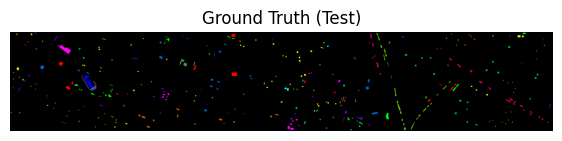

In [24]:
# ──────────────────────────────────────────────────────────────────────────
# Load the Houston 2013 dataset from .mat files.
# X            — raw hyperspectral cube  (H x W x Bands)
# Tr_labels    — training ground-truth   (H x W), 0 = unlabelled
# Te_labels    — testing ground-truth    (H x W), 0 = unlabelled
# gt           — combined ground-truth   (union of train + test labels)
# ──────────────────────────────────────────────────────────────────────────
X         = sio.loadmat(os.path.join(DATASET_DIR, 'Houston13_HSI.mat'))['data_HS_HR']
Tr_labels = sio.loadmat(os.path.join(DATASET_DIR, 'Houston_TrainImage.mat'))['TrainImage']
Te_labels = sio.loadmat(os.path.join(DATASET_DIR, 'Houston_TestImage.mat'))['TestImage']

gt        = Tr_labels + Te_labels
NUM_CLASS = int(Te_labels.max())

class_name = [
    'Healthy Grass', 'Stressed Grass', 'Synthetic Grass',
    'Tree', 'Soil', 'Water', 'Residential', 'Commercial',
    'Road', 'Highway', 'Railway', 'Parking Lot1',
    'Parking Lot2', 'Tennis Court', 'Running Track'
]

_, labels = get_img_indexes(gt, removeZeroindexes=True)

# Display the test ground-truth map
img_display(classes=Te_labels, title='Ground Truth (Test)', class_name=class_name)

# Apply PCA for dimensionality reduction
data = applyPCA(X, numComponents=NUM_PCA_COMPONENTS, normalization=True)

print(f'HSI cube shape after PCA: {data.shape}')
print(f'Number of classes: {NUM_CLASS}')

---
## Cell 9 — Train / Val / Test Split & Patch Extraction
Houston13 comes with predefined train/test splits.  
The training set is further halved into train + validation.  
Spatial patches of size `WINDOW_SIZE × WINDOW_SIZE` are extracted around each labelled pixel.

In [25]:
# ──────────────────────────────────────────────────────────────────────────
# Extract train / test indices from the predefined label maps, then
# split training into train + validation.
# ──────────────────────────────────────────────────────────────────────────
X_train_idx, y_train = get_img_indexes(Tr_labels, removeZeroindexes=True)
X_test_idx,  y_test  = get_img_indexes(Te_labels, removeZeroindexes=True)

num_samples_overall = len(X_train_idx) + len(X_test_idx)

X_train_idx, X_val_idx, y_train, y_val = splitTrainTestSet(
    X_train_idx, y_train, testRatio=VAL_SPLIT_RATIO
)

print("Training   Percentage =", format(100 * len(X_train_idx) / num_samples_overall, ".2f"), '%')
print("Validation Percentage =", format(100 * len(X_val_idx)   / num_samples_overall, ".2f"), '%')
print("Testing    Percentage =", format(100 * len(X_test_idx)  / num_samples_overall, ".2f"), '%')

# Per-class sample report
sample_report = f"{'class': ^25}{'train_num':^10}{'val_num': ^10}{'test_num': ^10}{'total': ^10}\n"
for i in np.unique(gt):
    if i == 0:
        continue
    sample_report += (f"{class_name[i-1]: ^25}"
                      f"{(y_train==i-1).sum(): ^10}"
                      f"{(y_val==i-1).sum(): ^10}"
                      f"{(y_test==i-1).sum(): ^10}"
                      f"{(gt==i).sum(): ^10}\n")
sample_report += (f"{'total': ^25}"
                  f"{len(y_train-1): ^10}"
                  f"{len(y_val): ^10}"
                  f"{len(y_test): ^10}"
                  f"{len(labels): ^10}")
print(sample_report)

# ──────────────────────────────────────────────────────────────────────────
# Create spatial patches and one-hot encode labels.
# ──────────────────────────────────────────────────────────────────────────
X_train = createImageCubes(data, X_train_idx, WINDOW_SIZE)
y_train = keras.utils.to_categorical(y_train)

X_val = createImageCubes(data, X_val_idx, WINDOW_SIZE)
y_val = keras.utils.to_categorical(y_val)

print(f'\nX_train shape: {X_train.shape}  |  y_train shape: {y_train.shape}')
print(f'X_val   shape: {X_val.shape}  |  y_val   shape: {y_val.shape}')

Training   Percentage = 9.42 %
Validation Percentage = 9.42 %
Testing    Percentage = 81.16 %
          class          train_num  val_num   test_num   total   
      Healthy Grass          99        99       1053      1251   
     Stressed Grass          95        95       1064      1254   
     Synthetic Grass         96        96       505       697    
          Tree               94        94       1056      1244   
          Soil               93        93       1056      1242   
          Water              91        91       143       325    
       Residential           98        98       1072      1268   
       Commercial            96        95       1053      1244   
          Road               97        96       1059      1252   
         Highway             95        96       1036      1227   
         Railway             90        91       1054      1235   
      Parking Lot1           96        96       1041      1233   
      Parking Lot2           92        92       

---
## Cell 10 — Build Model & Print Summary / FLOPs
Instantiates MixerSENet with the configured hyperparameters and prints the layer summary plus estimated FLOPs.

In [26]:
# ──────────────────────────────────────────────────────────────────────────
# Build the MixerSENet model and inspect it.
# ──────────────────────────────────────────────────────────────────────────
try:
    model = MixerSENet(
        img_list  = X_train,
        NumClasses = NUM_CLASS,
        depth     = DEPTH,
        filters   = FILTERS
    )
    model.summary()
    print()
    net_flops(model)
except Exception as e:
    import traceback
    traceback.print_exc()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 9, 9, 15)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 9, 9, 64)  │      1,024 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 9, 9, 64)  │          0 │ conv2d_11[0][0]   │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 9, 9, 64)  │        256 │ activation_1[0][… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d    │ (None, 9, 9, 64)  │        640 │ batch_normalizat… │
│ (DepthwiseConv2D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d_1  │ (None, 9, 9, 64)  │      1,664 │ batch_normalizat… │
│ (DepthwiseConv2D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d_2  │ (None, 9, 9, 64)  │      3,200 │ batch_normalizat… │
│ (DepthwiseConv2D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 9, 9, 64)  │          0 │ batch_normalizat… │
│                     │                   │            │ depthwise_conv2d… │
│                     │                   │            │ depthwise_conv2d… │
│                     │                   │            │ depthwise_conv2d… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cropping2d_5        │ (None, 1, 1, 64)  │          0 │ add_5[0][0]       │
│ (Cropping2D)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_5     │ (None, 9, 9, 64)  │          0 │ cropping2d_5[0][… │
│ (UpSampling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_5       │ (None, 9, 9, 128) │          0 │ add_5[0][0],      │
│ (Concatenate)       │                   │            │ up_sampling2d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 9, 9, 1)   │        129 │ concatenate_5[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_6          │ (None, 9, 9, 64)  │          0 │ conv2d_12[0][0],  │
│ (Multiply)          │                   │            │ add_5[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 9, 9, 64)  │      4,160 │ multiply_6[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 9, 9, 64)  │          0 │ conv2d_13[0][0]   │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 9, 9, 64)  │        256 │ activation_2[0][… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 9, 9, 64)  │          0 │ batch_normalizat… │
│                     │                   │            │ batch_normalizat

 Total params: 53,596 (209.36 KB)

 Trainable params: 52,828 (206.36 KB)

 Non-trainable params: 768 (3.00 KB)

Traceback (most recent call last):
  File "/tmp/ipykernel_1154/1244935528.py", line 13, in <cell line: 0>
    net_flops(model)
    ~~~~~~~~~^^^^^^^
  File "/tmp/ipykernel_1154/3010635720.py", line 47, in net_flops
    i_shape = _get_shape(l.input)[1:4]
              ~~~~~~~~~~^^^^^^^^^
  File "/tmp/ipykernel_1154/3010635720.py", line 16, in _get_shape
    t = tensor_or_list[0]
        ~~~~~~~~~~~~~~^^^
IndexError: list index out of range


---
## Cell 11 — Training
Trains the model with:
- `ModelCheckpoint` saving best weights by `val_accuracy`
- `ReduceLROnPlateau` halving the LR after 10 epochs without val-accuracy improvement

After training, the loss/accuracy curves are plotted.

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 731ms/step - accuracy: 0.2729 - loss: 2.4290
Epoch 1: val_accuracy improved from None to 0.17726, saving model to Houston_MixerSE_B1_(1).h5



Epoch 1: finished saving model to Houston_MixerSE_B1_(1).h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 47s 1s/step - accuracy: 0.4195 - loss: 1.9461 - val_accuracy: 0.1773 - val_loss: 2.6834 - learning_rate: 5.0000e-04
Epoch 2/100
19/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6715 - loss: 1.1590
Epoch 2: val_accuracy did not improve from 0.17726
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7133 - loss: 1.0387 - val_accuracy: 0.1201 - val_loss: 2.6663 - learning_rate: 5.0000e-04
Epoch 3/100
18/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8078 - loss: 0.7400
Epoch 3: val_accuracy did not improve from 0.17726
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8326 - loss: 0.6852 - val_accuracy: 0.0946 - val_loss: 2.6671 - learning_rate: 5.0000e-04
Epoch 4/100
21/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8604 - loss: 0.5368
Epoch 4: val_accuracy did not improve from 0.17726
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8538 - loss: 0.5450 - val_accuracy: 0.1462 -


Epoch 6: finished saving model to Houston_MixerSE_B1_(1).h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9103 - loss: 0.3556 - val_accuracy: 0.1836 - val_loss: 2.8149 - learning_rate: 5.0000e-04
Epoch 7/100
21/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9174 - loss: 0.3136
Epoch 7: val_accuracy improved from 0.18362 to 0.20339, saving model to Houston_MixerSE_B1_(1).h5



Epoch 7: finished saving model to Houston_MixerSE_B1_(1).h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9230 - loss: 0.3081 - val_accuracy: 0.2034 - val_loss: 2.8672 - learning_rate: 5.0000e-04
Epoch 8/100
22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9371 - loss: 0.2621
Epoch 8: val_accuracy improved from 0.20339 to 0.21186, saving model to Houston_MixerSE_B1_(1).h5



Epoch 8: finished saving model to Houston_MixerSE_B1_(1).h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.9258 - loss: 0.2767 - val_accuracy: 0.2119 - val_loss: 2.9172 - learning_rate: 5.0000e-04
Epoch 9/100
19/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9060 - loss: 0.3098
Epoch 9: val_accuracy did not improve from 0.21186
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9082 - loss: 0.3117 - val_accuracy: 0.1970 - val_loss: 2.9968 - learning_rate: 5.0000e-04
Epoch 10/100
20/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9067 - loss: 0.2838
Epoch 10: val_accuracy did not improve from 0.21186
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9145 - loss: 0.2699 - val_accuracy: 0.1949 - val_loss: 3.0156 - learning_rate: 5.0000e-04
Epoch 11/100
19/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9557 - loss: 0.1855
Epoch 11: val_accuracy did not improve from 0.21186
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9506 - loss: 0.1933 - val_accuracy: 0.205


Epoch 13: finished saving model to Houston_MixerSE_B1_(1).h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9379 - loss: 0.1894 - val_accuracy: 0.3150 - val_loss: 2.7461 - learning_rate: 5.0000e-04
Epoch 14/100
20/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9552 - loss: 0.1549
Epoch 14: val_accuracy improved from 0.31497 to 0.37288, saving model to Houston_MixerSE_B1_(1).h5


... (12 outputs left out)


Epoch 29: finished saving model to Houston_MixerSE_B1_(1).h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.9901 - loss: 0.0510 - val_accuracy: 0.9633 - val_loss: 0.1181 - learning_rate: 5.0000e-04
Epoch 30/100
20/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9814 - loss: 0.0674
Epoch 30: val_accuracy did not improve from 0.96328
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9823 - loss: 0.0723 - val_accuracy: 0.9393 - val_loss: 0.1592 - learning_rate: 5.0000e-04
Epoch 31/100
19/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9896 - loss: 0.0570
Epoch 31: val_accuracy did not improve from 0.96328
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9866 - loss: 0.0613 - val_accuracy: 0.9619 - val_loss: 0.1113 - learning_rate: 5.0000e-04
Epoch 32/100
19/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9803 - loss: 0.0690
Epoch 32: val_accuracy improved from 0.96328 to 0.97811, saving model to Houston_MixerSE_B1_(1).h5



Epoch 32: finished saving model to Houston_MixerSE_B1_(1).h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.9838 - loss: 0.0620 - val_accuracy: 0.9781 - val_loss: 0.0917 - learning_rate: 5.0000e-04
Epoch 33/100
19/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9853 - loss: 0.0595
Epoch 33: val_accuracy did not improve from 0.97811
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9866 - loss: 0.0543 - val_accuracy: 0.9555 - val_loss: 0.1703 - learning_rate: 5.0000e-04
Epoch 34/100
19/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9863 - loss: 0.0595
Epoch 34: val_accuracy did not improve from 0.97811
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9838 - loss: 0.0678 - val_accuracy: 0.9463 - val_loss: 0.1507 - learning_rate: 5.0000e-04
Epoch 35/100
20/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9803 - loss: 0.0787
Epoch 35: val_accuracy did not improve from 0.97811
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9809 - loss: 0.0815 - val_accuracy: 0.


Epoch 38: finished saving model to Houston_MixerSE_B1_(1).h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.9922 - loss: 0.0391 - val_accuracy: 0.9845 - val_loss: 0.0630 - learning_rate: 5.0000e-04
Epoch 39/100
19/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9794 - loss: 0.0727
Epoch 39: val_accuracy did not improve from 0.98446
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9809 - loss: 0.0714 - val_accuracy: 0.9788 - val_loss: 0.0702 - learning_rate: 5.0000e-04
Epoch 40/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9918 - loss: 0.0426
Epoch 40: val_accuracy improved from 0.98446 to 0.99223, saving model to Houston_MixerSE_B1_(1).h5



Epoch 40: finished saving model to Houston_MixerSE_B1_(1).h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9901 - loss: 0.0428 - val_accuracy: 0.9922 - val_loss: 0.0367 - learning_rate: 5.0000e-04
Epoch 41/100
19/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9960 - loss: 0.0283
Epoch 41: val_accuracy did not improve from 0.99223
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9929 - loss: 0.0371 - val_accuracy: 0.9640 - val_loss: 0.1095 - learning_rate: 5.0000e-04
Epoch 42/100
19/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9900 - loss: 0.0446
Epoch 42: val_accuracy did not improve from 0.99223
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.9894 - loss: 0.0441 - val_accuracy: 0.9435 - val_loss: 0.1833 - learning_rate: 5.0000e-04
Epoch 43/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9817 - loss: 0.0583
Epoch 43: val_accuracy did not improve from 0.99223
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9823 - loss: 0.0590 - val_accuracy: 0

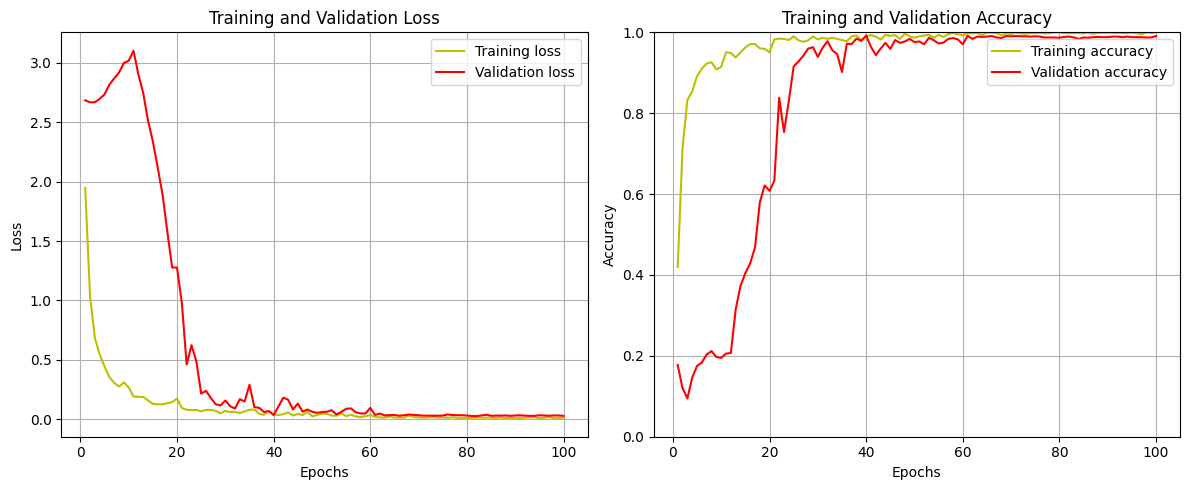

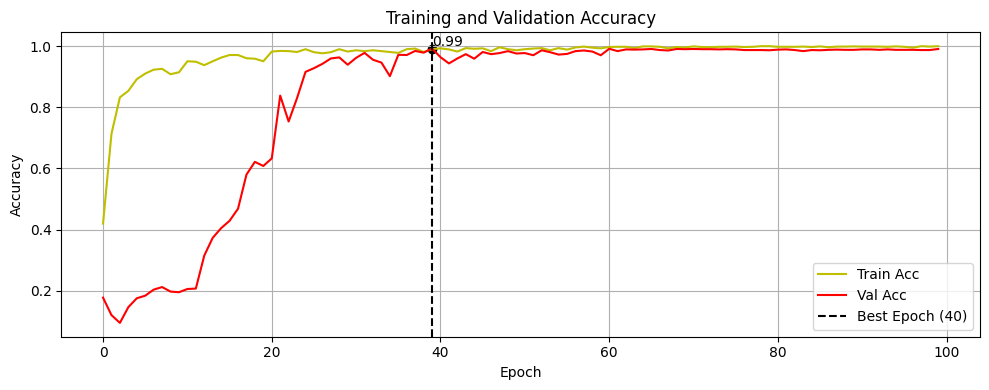

In [27]:
# ──────────────────────────────────────────────────────────────────────────
# Callbacks: save best weights + reduce learning rate on plateau.
# ──────────────────────────────────────────────────────────────────────────
checkpoint = ModelCheckpoint(
    CHECKPOINT_PATH,
    monitor='val_accuracy',
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

lr_callback = keras.callbacks.ReduceLROnPlateau(
    monitor='val_accuracy',
    factor=0.5,
    patience=10,
    min_lr=5e-5
)

# ──────────────────────────────────────────────────────────────────────────
# Train the model.
# ──────────────────────────────────────────────────────────────────────────
history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val),
    callbacks=[checkpoint, lr_callback],
)

# Plot training history
display_history(history)

---
## Cell 12 — Evaluation (OA, AA, Kappa)
Loads the best checkpoint, runs batched inference on the test set, and computes Overall Accuracy, Average Accuracy, and Cohen's Kappa.

Progress: 100%|██████████| 13/13 [00:09<00:00,  1.43it/s]


Overall Accuracy = 79.48
Average Accuracy = 82.97
Kappa            = 77.79

Per-class accuracy:
  Healthy Grass               80.15%
  Stressed Grass              83.65%
  Synthetic Grass             96.83%
  Tree                        81.25%
  Soil                       100.00%
  Water                       95.80%
  Residential                 91.04%
  Commercial                  61.16%
  Road                        76.30%
  Highway                     40.93%
  Railway                     66.41%
  Parking Lot1                87.51%
  Parking Lot2                84.21%
  Tennis Court               100.00%
  Running Track               99.37%


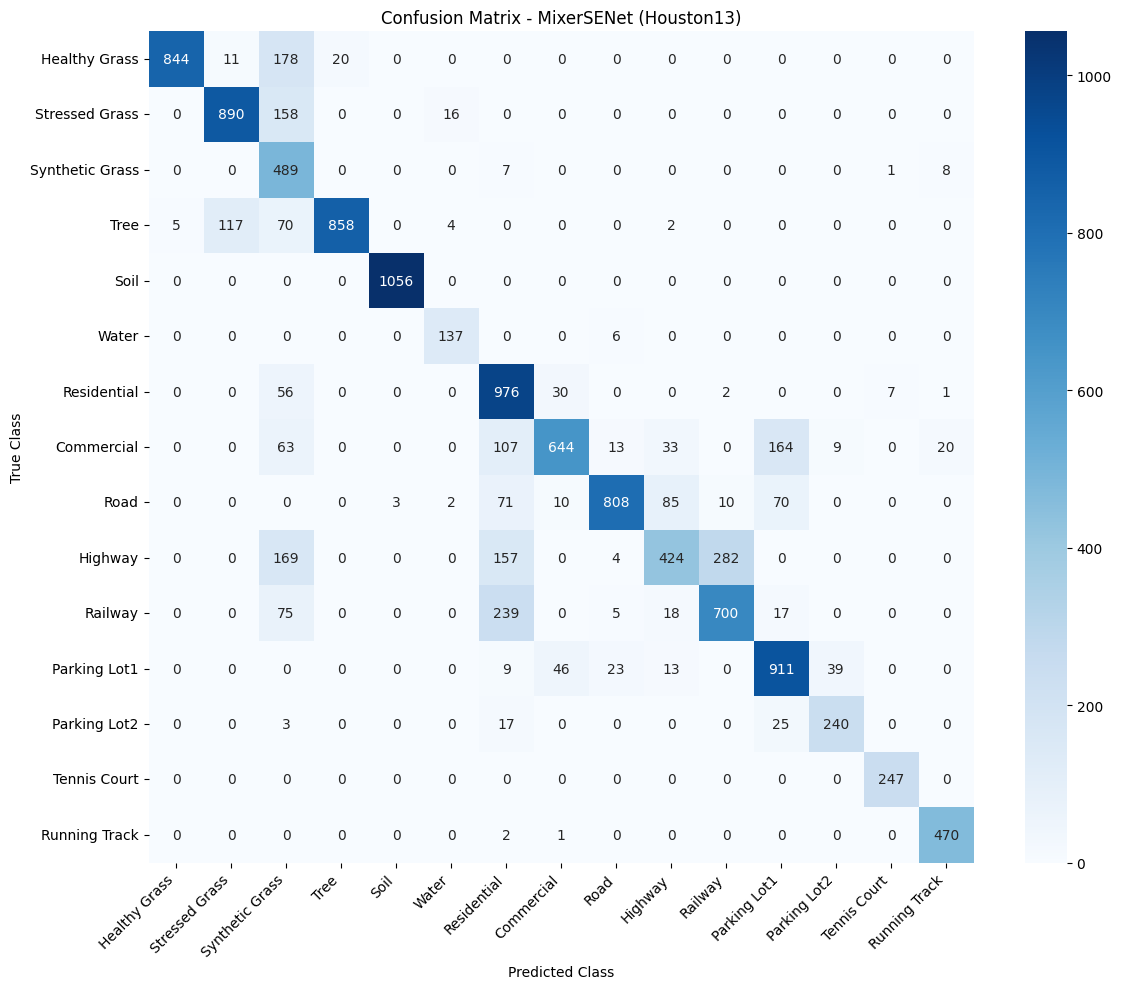

In [28]:
# ──────────────────────────────────────────────────────────────────────────
# Load the best weights and evaluate on the held-out test set.
# ──────────────────────────────────────────────────────────────────────────
model.load_weights(CHECKPOINT_PATH)

# Re-extract test labels (before one-hot) since y_test may have been
# overwritten during patching; reuse the original indices.
_, y_test_eval = get_img_indexes(Te_labels, removeZeroindexes=True)

Y_pred_test  = predict_by_batching(
    model, input_tensor_idx=X_test_idx,
    batch_size=1000, X=data, windowSize=WINDOW_SIZE
)
y_pred_test  = np.argmax(Y_pred_test, axis=1)

kappa     = cohen_kappa_score(y_test_eval, y_pred_test)
oa        = accuracy_score(y_test_eval, y_pred_test)
cm        = confusion_matrix(y_test_eval, y_pred_test)
class_acc = cm.diagonal() / cm.sum(axis=1)
aa        = np.mean(class_acc)

print("Overall Accuracy =", float(format(oa * 100, ".2f")))
print("Average Accuracy =", float(format(aa * 100, ".2f")))
print("Kappa            =", float(format(kappa * 100, ".2f")))
print("\nPer-class accuracy:")
for idx, (name, acc) in enumerate(zip(class_name, class_acc)):
    print(f"  {name:25s}  {acc*100:6.2f}%")

# ──────────────────────────────────────────────────────────────────────────
# Plot the Confusion Matrix
# ──────────────────────────────────────────────────────────────────────────
import seaborn as sns
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_name,
    yticklabels=class_name
)
plt.title("Confusion Matrix - MixerSENet (Houston13)")
plt.ylabel("True Class")
plt.xlabel("Predicted Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

---
## Cell 13 — Classification Map Generation & Visualisation
Generates the full predicted class map for the entire image and displays it alongside a masked version (only where ground truth is available).

Progress: 100%|██████████| 67/67 [01:44<00:00,  1.56s/it]


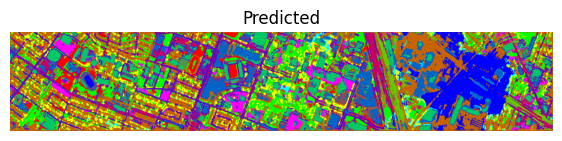

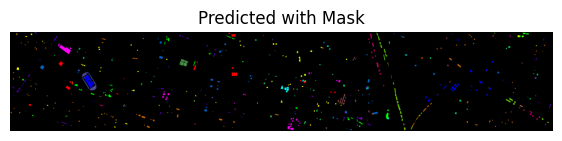

In [29]:
# ──────────────────────────────────────────────────────────────────────────
# Generate the full predicted class map and visualise.
# ──────────────────────────────────────────────────────────────────────────
model.load_weights(CHECKPOINT_PATH)

Predicted_Class_Map = get_class_map(model, data, gt, WINDOW_SIZE)
img_display(classes=Predicted_Class_Map, title='Predicted', class_name=class_name)

# Masked version — show predictions only where ground truth exists
gt_binary = gt.copy()
gt_binary[gt > 0] = 1
img_display(
    classes=Predicted_Class_Map * gt_binary,
    title='Predicted with Mask',
    class_name=class_name
)

---
## Cell 14 — Save Results to .mat File
Exports the predicted classification map as a MATLAB `.mat` file for external analysis.

In [30]:
# ──────────────────────────────────────────────────────────────────────────
# Save the predicted class map as a .mat file.
# ──────────────────────────────────────────────────────────────────────────
OUTPUT_FOLDER = 'Matlab_Outputs'
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

Name = 'Houston_MixerSENet_B1_(1)'
sio.savemat(
    os.path.join(OUTPUT_FOLDER, Name + '.mat'),
    {Name: Predicted_Class_Map}
)

print(f'Saved: {os.path.join(OUTPUT_FOLDER, Name + ".mat")}')

Saved: Matlab_Outputs/Houston_MixerSENet_B1_(1).mat
